# Sleep Debt and Screen Time Analysis Using Python

**EDAV Case Study Project**  
**Department:** Information Technology  
**College:** Chaitanya Bharathi Institute of Technology (CBIT)

## Executive Summary and Objective
Sleep is important for physical health, concentration and daily functioning. This exploratory data analysis examines associations between bedtime smartphone use, sleep duration, sleep debt, fatigue and lifestyle characteristics. The project uses Pandas for data preparation and aggregation, and Matplotlib and Seaborn for visual exploration. Its results describe patterns in the supplied dataset rather than demonstrating causal effects.

## Key Research Questions
1. How does bedtime phone use relate to sleep duration and sleep debt?
2. Which occupations and chronotypes show higher average fatigue?
3. How are evening caffeine intake and sleep latency associated?
4. Does physical activity vary with sleep duration and fatigue?
5. What patterns appear across gender and age groups?

## Research Goals
- Clean and summarize the data.
- Create useful screen-time and sleep-duration groups.
- Compare group averages and distributions.
- Visualize relationships and compute correlations.
- Interpret patterns without overstating causal conclusions.

## Dataset
**Source:** Kaggle — *Sleep Debt and Screen Time: Late Night Phone Habits* (dataset identifier: `samartalwar/sleep-debt-and-screen-time-late-night-phone-habits`). The notebook downloads and reads `bedtime_screentime_sleep_debt.csv`. Variables include age, gender, occupation, chronotype, bedtime phone minutes, evening caffeine, activity, sleep latency, sleep hours, alarm snoozes, fatigue score and a supplied sleep-debt category.


## 1. Importing Libraries and Downloading the Dataset

This section imports the libraries needed for data manipulation and downloads the Sleep Debt and Screen Time dataset from Kaggle. The downloaded directory is inspected to locate the dataset file.


In [ ]:
import kagglehub
import pandas as pd
import os

# Download the latest version of the dataset
path = kagglehub.dataset_download(
    "samartalwar/sleep-debt-and-screen-time-late-night-phone-habits"
)

print("Path to dataset files:", path)

# Check files downloaded
print("\nFiles in dataset folder:")
print(os.listdir(path))


Using Colab cache for faster access to the 'sleep-debt-and-screen-time-late-night-phone-habits' dataset.
Path to dataset files: /kaggle/input/sleep-debt-and-screen-time-late-night-phone-habits

Files in dataset folder:
['bedtime_screentime_sleep_debt.csv']


## 2. Loading and Previewing the Dataset

The CSV file is loaded into a Pandas DataFrame. Displaying the first five records helps verify the file was read correctly and provides an initial view of the variables.


In [ ]:
# Load the CSV file
df = pd.read_csv(os.path.join(path, "bedtime_screentime_sleep_debt.csv"))

# Display first 5 rows
print(df.head())

     user_id  age      gender            occupation_type    chronotype  \
0  USR-00001   29      Female  Healthcare / Shift Worker  Intermediate   
1  USR-00002   58      Female                    Student  Intermediate   
2  USR-00003   41      Female  Healthcare / Shift Worker     Night Owl   
3  USR-00004   36  Non-Binary                Remote Tech  Intermediate   
4  USR-00005   23      Female  Healthcare / Shift Worker  Intermediate   

   bedtime_phone_minutes primary_bedtime_app  screen_brightness_pct  \
0                    179  Instagram / Reddit                     54   
1                    163             YouTube                     76   
2                    100      TikTok / Reels                     59   
3                     34             YouTube                     52   
4                     27      TikTok / Reels                     82   

   blue_light_filter_active  caffeine_post_5pm_mg  physical_activity_min  \
0                         1                     0   

## 3. Initial Dataset Inspection

We inspect dataset dimensions, column names, data types, missing values and duplicate records. This initial quality check identifies potential issues that should be addressed before analysis.


In [ ]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset Information:")
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())



Shape: (8500, 18)

Columns:
['user_id', 'age', 'gender', 'occupation_type', 'chronotype', 'bedtime_phone_minutes', 'primary_bedtime_app', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score', 'sleep_debt_category']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-

## 4. Selecting Relevant Attributes

Only variables relevant to the research questions are retained, including demographic characteristics, bedtime phone use, caffeine intake, activity, sleep duration, sleep latency and fatigue. This reduces unnecessary complexity.


In [ ]:
#Selecting important attributes
selected_columns = [
    "age",
    "gender",
    "occupation_type",
    "chronotype",
    "bedtime_phone_minutes",
    "primary_bedtime_app",
    "caffeine_post_5pm_mg",
    "physical_activity_min",
    "sleep_latency_min",
    "total_sleep_hours",
    "morning_alarm_snoozes",
    "next_day_fatigue_score",
    "sleep_debt_category"
]

df = df[selected_columns]

print("New dataset shape:", df.shape)
print(df.head())

New dataset shape: (8500, 13)
   age      gender            occupation_type    chronotype  \
0   29      Female  Healthcare / Shift Worker  Intermediate   
1   58      Female                    Student  Intermediate   
2   41      Female  Healthcare / Shift Worker     Night Owl   
3   36  Non-Binary                Remote Tech  Intermediate   
4   23      Female  Healthcare / Shift Worker  Intermediate   

   bedtime_phone_minutes primary_bedtime_app  caffeine_post_5pm_mg  \
0                    179  Instagram / Reddit                     0   
1                    163             YouTube                    92   
2                    100      TikTok / Reels                    45   
3                     34             YouTube                    97   
4                     27      TikTok / Reels                     0   

   physical_activity_min  sleep_latency_min  total_sleep_hours  \
0                     21               84.4               3.20   
1                     72              

## 5. Renaming Columns for Readability

Long column names are replaced with shorter descriptive names. Consistent naming makes later calculations, groupings and visualizations easier to understand.


In [ ]:
# Rename columns for readability

df = df.rename(columns={
    "bedtime_phone_minutes": "phone_minutes",
    "primary_bedtime_app": "bedtime_app",
    "caffeine_post_5pm_mg": "evening_caffeine_mg",
    "physical_activity_min": "physical_activity_minutes",
    "sleep_latency_min": "sleep_latency_minutes",
    "total_sleep_hours": "sleep_hours",
    "morning_alarm_snoozes": "alarm_snoozes",
    "next_day_fatigue_score": "fatigue_score"
})

## 6. Creating Analytical Categories

Continuous variables are grouped into interpretable categories using Pandas `cut()`. Phone use is classified as low, moderate, high or very high; sleep duration and age are also grouped to support comparisons. These are project-specific analytical bands, not clinical diagnoses.


In [ ]:
#Create screen-time categories


df["phone_usage_category"] = pd.cut(
    df["phone_minutes"],
    bins=[-1, 30, 60, 120, float("inf")],
    labels=["Low", "Moderate", "High", "Very High"]
)


#Create sleep-duration categories


df["sleep_duration_category"] = pd.cut(
    df["sleep_hours"],
    bins=[0, 6, 7, 8, float("inf")],
    labels=["Short", "Moderate", "Recommended", "Long"]
)


#Create age groups



df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 18, 25, 35, 50, 100],
    labels=[
        "Under 18",
        "18-25",
        "26-35",
        "36-50",
        "50+"
    ]
)

## 7. Handling Missing Values and Duplicate Records

Duplicate records are removed. Missing numerical values are replaced with the corresponding column median and missing categorical values with the most common category. This prepares a more consistent dataset, although imputation can influence subsequent findings.


In [ ]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values with median
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nAfter Cleaning:")
print("Shape:", df.shape)
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age                          0
gender                       0
occupation_type              0
chronotype                   0
phone_minutes                0
bedtime_app                  0
evening_caffeine_mg          0
physical_activity_minutes    0
sleep_latency_minutes        0
sleep_hours                  0
alarm_snoozes                0
fatigue_score                0
sleep_debt_category          0
phone_usage_category         0
sleep_duration_category      0
age_group                    0
dtype: int64

Duplicate Rows: 0

After Cleaning:
Shape: (8500, 16)
Missing Values:
age                          0
gender                       0
occupation_type              0
chronotype                   0
phone_minutes                0
bedtime_app                  0
evening_caffeine_mg          0
physical_activity_minutes    0
sleep_latency_minutes        0
sleep_hours                  0
alarm_snoozes                0
fatigue_score                0
sleep_debt_category          0
ph

## 8. Descriptive Statistics and Sleep Debt Distribution

Summary statistics describe central tendency, spread and ranges of numerical variables. Categorical frequencies and percentages show the composition of the dataset and the distribution of sleep-debt labels.


In [ ]:
# Overall numerical summary
print("Numerical Summary:")
display(df.describe().round(2))

# Summary of categorical columns
print("\nCategorical Summary:")
display(df.describe(include="object"))

# Distribution of sleep debt
print("\nSleep Debt Category Counts:")
display(df["sleep_debt_category"].value_counts())

print("\nSleep Debt Category Percentages:")
display(
    (df["sleep_debt_category"]
     .value_counts(normalize=True) * 100).round(2)
)

# Key averages
print("\nAverage phone use before bed:",
      round(df["phone_minutes"].mean(), 2), "minutes")

print("Average sleep duration:",
      round(df["sleep_hours"].mean(), 2), "hours")

print("Average next-day fatigue score:",
      round(df["fatigue_score"].mean(), 2))

Numerical Summary:


,age,phone_minutes,evening_caffeine_mg,physical_activity_minutes,sleep_latency_minutes,sleep_hours,alarm_snoozes,fatigue_score
count,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00
mean,34.36,59.25,33.22,35.70,40.67,6.27,2.77,3.79
std,11.58,36.93,51.94,20.82,17.44,1.45,1.70,2.69
min,18.00,1.00,0.00,0.00,6.00,3.20,0.00,1.00
25%,25.00,31.00,0.00,21.00,28.20,5.24,2.00,1.10
50%,32.00,51.00,0.00,35.00,37.60,6.33,3.00,3.20
75%,42.00,79.00,55.00,50.00,49.70,7.35,4.00,5.60
max,65.00,180.00,250.00,112.00,123.30,9.80,7.00,10.00



Categorical Summary:


,gender,occupation_type,chronotype,bedtime_app,sleep_debt_category
count,8500,8500,8500,8500,8500
unique,3,5,3,6,4
top,Female,Corporate 9-to-5,Intermediate,TikTok / Reels,Moderate Debt
freq,4347,2838,3880,2198,4462



Sleep Debt Category Counts:


,count
sleep_debt_category,
Moderate Debt,4462
Mild Deficit,2004
Optimal Recovery,1387
Severe Sleep Debt,647



Sleep Debt Category Percentages:


,proportion
sleep_debt_category,
Moderate Debt,52.49
Mild Deficit,23.58
Optimal Recovery,16.32
Severe Sleep Debt,7.61



Average phone use before bed: 59.25 minutes
Average sleep duration: 6.27 hours
Average next-day fatigue score: 3.79


## 9. Bedtime Phone Usage Across Sleep Debt Categories

We group observations by sleep-debt category and calculate average bedtime phone minutes, sleep hours, fatigue and participant counts. The comparison explores associations but does not establish that phone use causes sleep debt.


In [ ]:
# Question 1: Does phone usage differ by sleep-debt category?
phone_sleep_debt = df.groupby(
    "sleep_debt_category", observed=True
).agg(
    average_phone_minutes=("phone_minutes", "mean"),
    average_sleep_hours=("sleep_hours", "mean"),
    average_fatigue=("fatigue_score", "mean"),
    participant_count=("sleep_debt_category", "size")
).round(2)

display(phone_sleep_debt)

,average_phone_minutes,average_sleep_hours,average_fatigue,participant_count
sleep_debt_category,,,,
Mild Deficit,45.45,7.23,1.83,2004
Moderate Debt,64.12,5.55,4.68,4462
Optimal Recovery,33.51,8.35,1.08,1387
Severe Sleep Debt,123.60,3.76,9.58,647


## 10. Occupation-Wise Fatigue Analysis

This analysis compares average fatigue, sleep duration and bedtime phone use across occupation types. Sorting by fatigue highlights occupational groups with higher reported fatigue in the sample.


In [ ]:
# Question 2: Which occupations have higher average fatigue?
occupation_analysis = df.groupby("occupation_type").agg(
    average_fatigue=("fatigue_score", "mean"),
    average_sleep_hours=("sleep_hours", "mean"),
    average_phone_minutes=("phone_minutes", "mean"),
    participant_count=("occupation_type", "size")
).sort_values("average_fatigue", ascending=False).round(2)

display(occupation_analysis)

,average_fatigue,average_sleep_hours,average_phone_minutes,participant_count
occupation_type,,,,
Healthcare / Shift Worker,5.54,5.02,59.30,997
Freelance / Creative,3.68,6.38,60.04,901
Corporate 9-to-5,3.57,6.43,59.07,2838
Remote Tech,3.54,6.45,59.40,2142
Student,3.51,6.45,58.89,1622


## 11. Chronotype and Sleep Patterns

Chronotype refers to an individual’s preference for earlier or later sleep-wake timing. Grouped averages allow comparison of sleep hours, fatigue and bedtime phone use across chronotype groups.


In [ ]:
# Question 3: Does chronotype relate to sleep duration and fatigue?
chronotype_analysis = df.groupby("chronotype").agg(
    average_sleep_hours=("sleep_hours", "mean"),
    average_fatigue=("fatigue_score", "mean"),
    average_phone_minutes=("phone_minutes", "mean")
).round(2)

display(chronotype_analysis)

,average_sleep_hours,average_fatigue,average_phone_minutes
chronotype,,,
Intermediate,6.44,3.48,59.57
Morning Lark,7.38,2.53,59.75
Night Owl,5.01,5.40,58.31


## 12. Evening Caffeine and Sleep Latency

Evening caffeine intake is divided into consumption bands, and average sleep latency and duration are compared. Sleep latency means the time taken to fall asleep; observed patterns may also reflect other lifestyle factors.


In [ ]:
# Question 4: Is evening caffeine associated with sleep latency?
caffeine_analysis = df.groupby(
    pd.cut(
        df["evening_caffeine_mg"],
        bins=[-1, 0, 50, 100, float("inf")],
        labels=["None", "1-50 mg", "51-100 mg", "Over 100 mg"]
    ),
    observed=True
).agg(
    average_sleep_latency=("sleep_latency_minutes", "mean"),
    average_sleep_hours=("sleep_hours", "mean"),
    participant_count=("evening_caffeine_mg", "size")
).round(2)

display(caffeine_analysis)

,average_sleep_latency,average_sleep_hours,participant_count
evening_caffeine_mg,,,
None,38.51,6.30,4950
1-50 mg,40.66,6.26,1278
51-100 mg,43.29,6.23,1267
Over 100 mg,48.06,6.14,1005


## 13. Physical Activity and Sleep Outcomes

Physical activity is divided into four duration bands. Group-level averages help investigate whether reported activity is associated with sleep hours or next-day fatigue.


In [ ]:
#Does physical activity relate to sleep duration and fatigue?
activity_analysis = df.groupby(
    pd.cut(
        df["physical_activity_minutes"],
        bins=[-1, 30, 60, 90, float("inf")],
        labels=["Low", "Moderate", "High", "Very High"]
    ),
    observed=True
).agg(
    average_sleep_hours=("sleep_hours", "mean"),
    average_fatigue=("fatigue_score", "mean"),
    participant_count=("physical_activity_minutes", "size")
).round(2)

display(activity_analysis)

,average_sleep_hours,average_fatigue,participant_count
physical_activity_minutes,,,
Low,6.25,3.91,3521
Moderate,6.28,3.73,3942
High,6.27,3.68,985
Very High,6.49,3.21,52


## 14. Age Distribution — Histogram

A histogram shows how participants are distributed across age ranges. This helps assess whether the sample is concentrated in particular age groups.


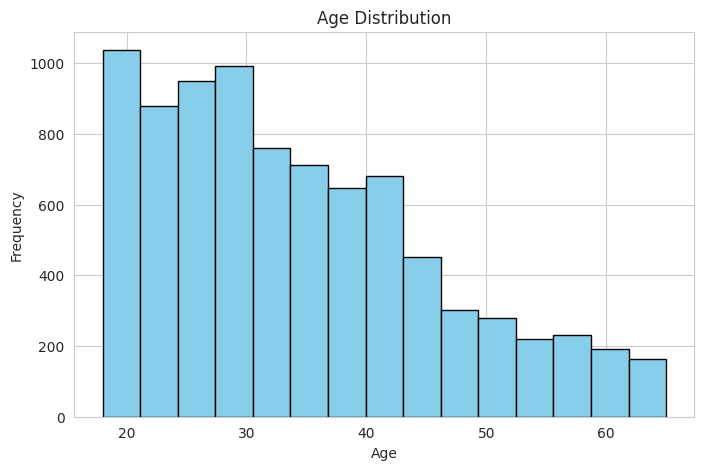

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.figure(figsize=(8,5))

plt.hist(df["age"], bins=15, color="skyblue", edgecolor="black")

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

## 15. Sleep Duration Distribution — Histogram

This histogram shows the frequency of different sleep durations. It helps identify the most common sleep ranges and any unusually short or long reported durations.


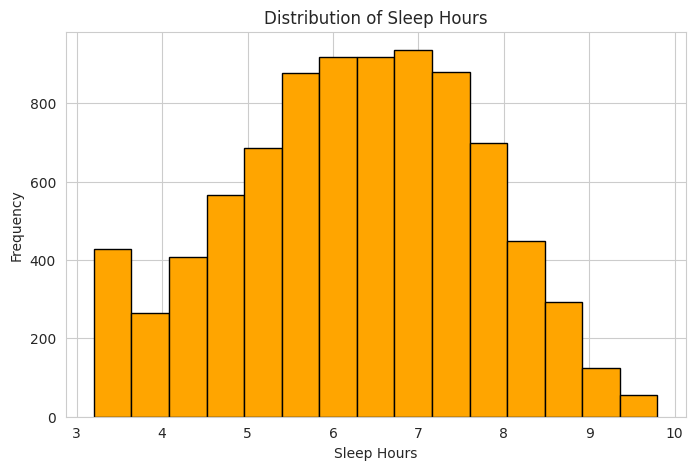

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["sleep_hours"], bins=15, color="orange", edgecolor="black")

plt.title("Distribution of Sleep Hours")
plt.xlabel("Sleep Hours")
plt.ylabel("Frequency")

plt.show()

## 16. Sleep Duration Categories — Pie Chart

The pie chart shows the relative proportions of the project-defined sleep duration categories, making the overall composition easy to compare.


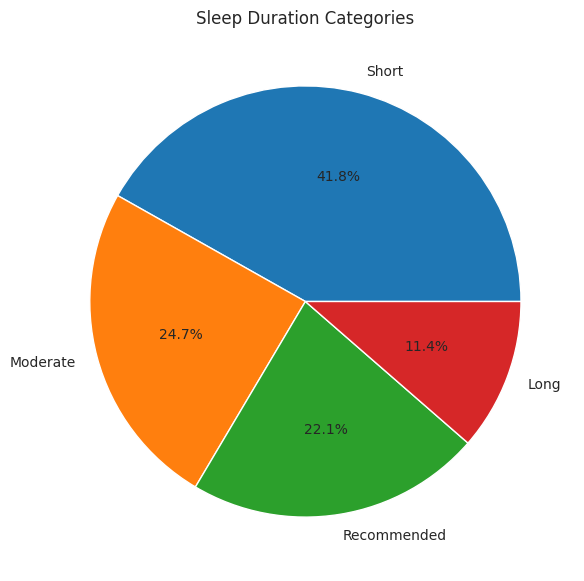

In [ ]:
plt.figure(figsize=(7,7))

df["sleep_duration_category"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Sleep Duration Categories")
plt.ylabel("")

plt.show()

## 17. Gender Distribution — Count Plot

A count plot displays the number of observations in each recorded gender category. Sample composition should be considered when interpreting gender-based comparisons.


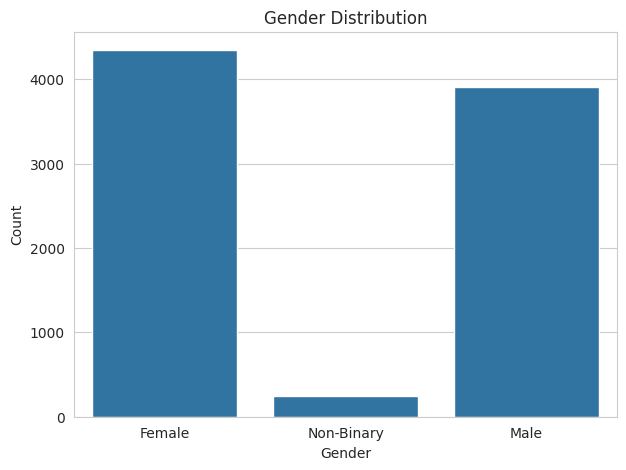

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.show()

## 18. Sleep Debt Category Distribution — Count Plot

This chart displays how frequently each sleep-debt category appears in the dataset. It provides a visual counterpart to the earlier frequency table.


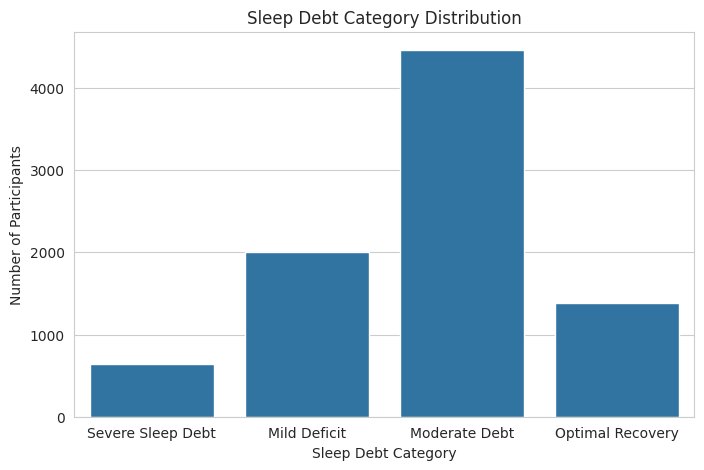

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="sleep_debt_category")

plt.title("Sleep Debt Category Distribution")
plt.xlabel("Sleep Debt Category")
plt.ylabel("Number of Participants")

plt.show()

## 19. Bedtime Phone Use Versus Sleep Duration — Scatter Plot

Each point represents an observation, with bedtime phone minutes on the horizontal axis and sleep hours on the vertical axis. Color indicates gender, helping explore whether the relationship differs across groups.


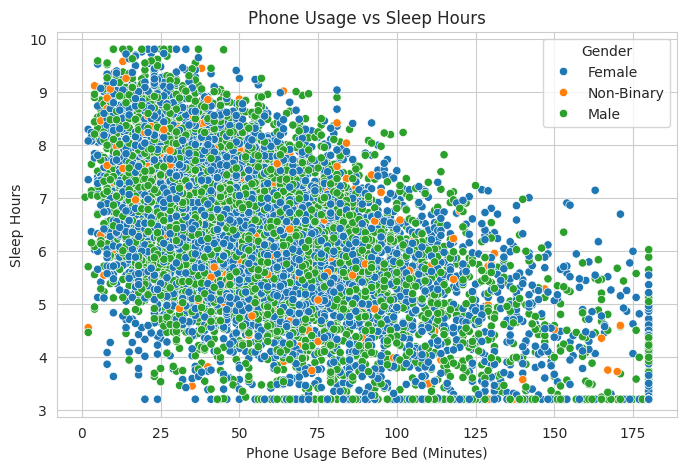

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="phone_minutes",
    y="sleep_hours",
    hue="gender"
)

plt.title("Phone Usage vs Sleep Hours")
plt.xlabel("Phone Usage Before Bed (Minutes)")
plt.ylabel("Sleep Hours")
plt.legend(title="Gender")

plt.show()



20. Impact of Different Applications on Sleep Duration — Bar Plot

This bar graph compares the average sleep duration associated with different applications used before bedtime. It helps identify which applications are associated with shorter or longer sleeping hours.

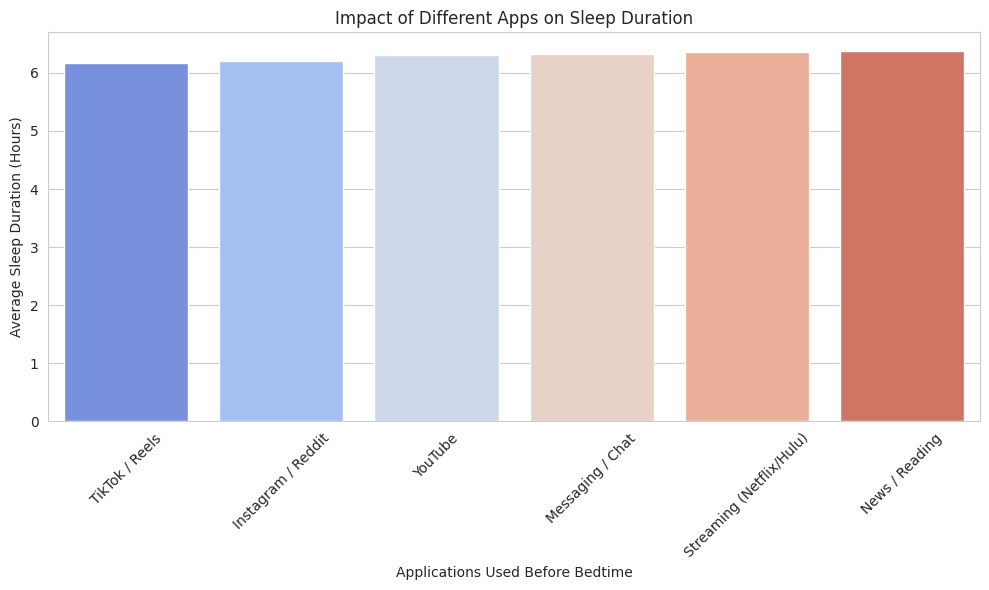

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

app_sleep = df.groupby("bedtime_app")["sleep_hours"].mean().sort_values()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=app_sleep.index,
    y=app_sleep.values,
    hue=app_sleep.index,
    palette="coolwarm",
    legend=False
)

plt.title("Impact of Different Apps on Sleep Duration")
plt.xlabel("Applications Used Before Bedtime")
plt.ylabel("Average Sleep Duration (Hours)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 21. Phone Usage Categories Versus Average Fatigue — Line Plot

The mean fatigue score is calculated for each screen-time category and plotted in category order. This helps visualize differences in average fatigue across phone-use groups; the connected line does not imply a continuous time trend.


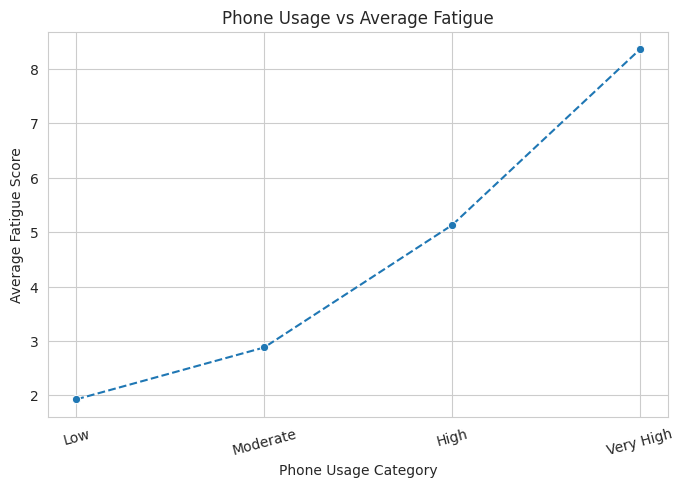

In [ ]:
phone_fatigue = df.groupby(
    "phone_usage_category",
    observed=True
)["fatigue_score"].mean().reset_index()

plt.figure(figsize=(8,5))

sns.lineplot(
    data=phone_fatigue,
    x="phone_usage_category",
    y="fatigue_score",
    marker="o",
    linestyle="--"
)

plt.title("Phone Usage vs Average Fatigue")
plt.xlabel("Phone Usage Category")
plt.ylabel("Average Fatigue Score")
plt.xticks(rotation=15)

plt.show()

## 22. Occupation Versus Average Sleep Hours — Bar Chart

A bar chart compares mean sleep duration across occupations. Differences may reflect schedules, work demands and other unmeasured factors.


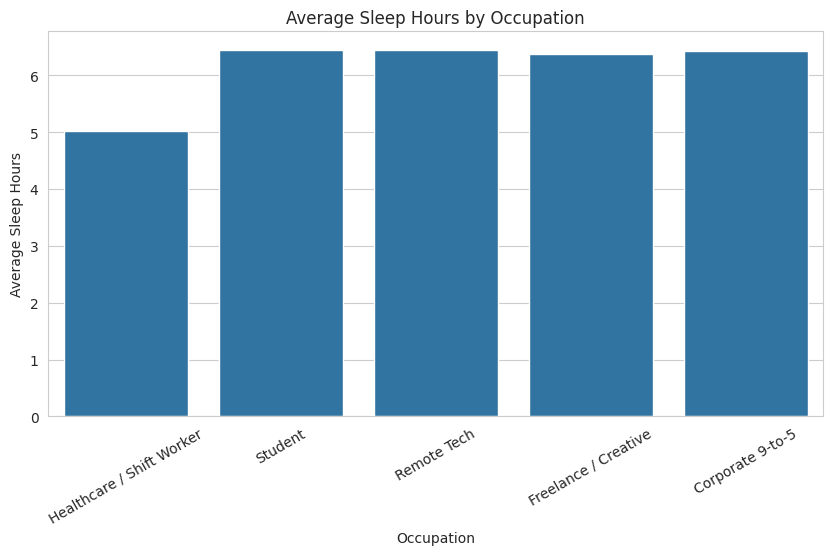

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
    x="occupation_type",
    y="sleep_hours",
    errorbar=None
)

plt.title("Average Sleep Hours by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Average Sleep Hours")
plt.xticks(rotation=30)

plt.show()

## 23. Sleep Duration by Gender — Box Plot

Box plots compare the median, interquartile range and potential outliers in sleep hours for each gender category. They reveal variation that averages alone may hide.


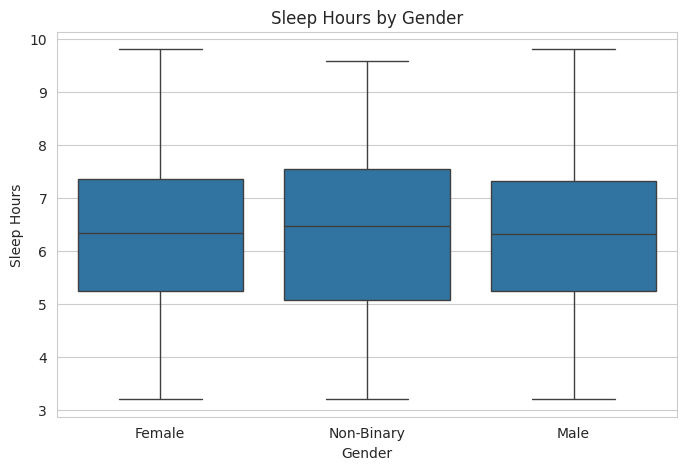

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="gender",
    y="sleep_hours"
)

plt.title("Sleep Hours by Gender")
plt.xlabel("Gender")
plt.ylabel("Sleep Hours")

plt.show()

## 24. Chronotype Distribution — Count Plot

This visualization shows how many observations belong to each chronotype category, providing context for the chronotype comparison.


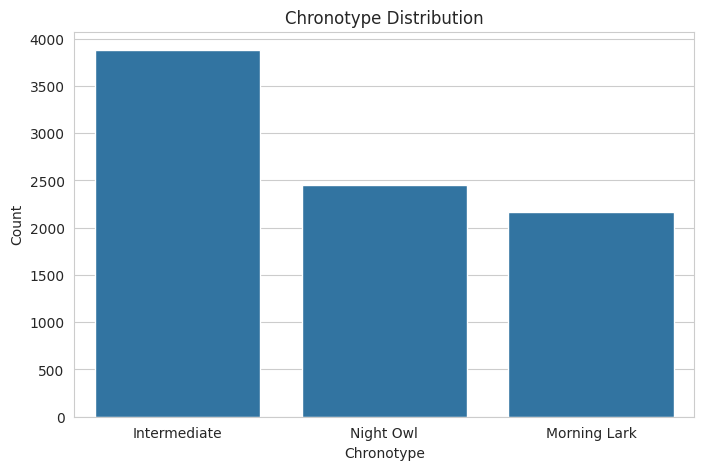

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="chronotype")

plt.title("Chronotype Distribution")
plt.xlabel("Chronotype")
plt.ylabel("Count")

plt.show()

## 25. Evening Caffeine Versus Sleep Latency — Scatter Plot

This plot examines whether higher evening caffeine intake is associated with longer sleep latency. The scatter of points indicates variability and should not be interpreted as proof of causation.


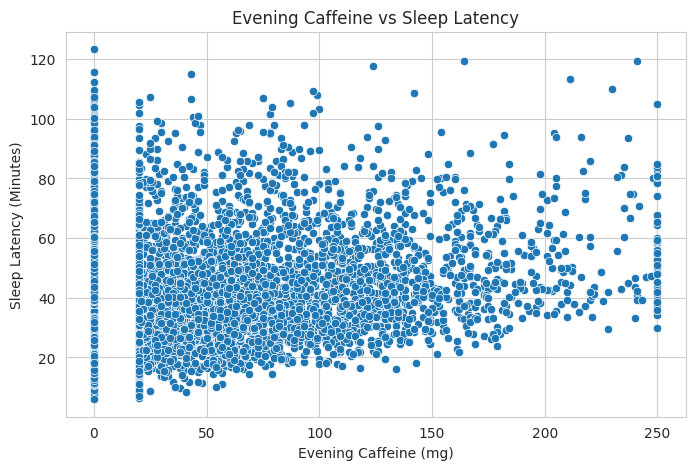

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="evening_caffeine_mg",
    y="sleep_latency_minutes"
)

plt.title("Evening Caffeine vs Sleep Latency")
plt.xlabel("Evening Caffeine (mg)")
plt.ylabel("Sleep Latency (Minutes)")

plt.show()

## 26. Alarm Snoozes Versus Fatigue — Scatter Plot

This scatter plot compares the number of morning alarm snoozes with next-day fatigue scores. It explores whether frequent snoozing tends to coincide with greater reported tiredness.


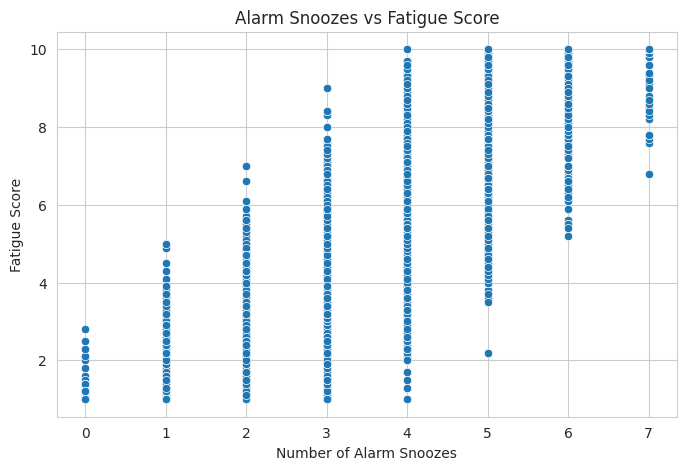

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="alarm_snoozes",
    y="fatigue_score"
)

plt.title("Alarm Snoozes vs Fatigue Score")
plt.xlabel("Number of Alarm Snoozes")
plt.ylabel("Fatigue Score")

plt.show()

## 27. Correlation Matrix and Heatmap

Pearson correlation coefficients summarize linear relationships between numerical variables. Values range from −1 to +1; correlation does not imply causation, and weak linear correlation does not rule out nonlinear patterns.


,age,phone_minutes,evening_caffeine_mg,physical_activity_minutes,sleep_latency_minutes,sleep_hours,alarm_snoozes,fatigue_score
age,1.00,-0.02,-0.01,-0.01,-0.06,0.02,-0.03,-0.03
phone_minutes,-0.02,1.00,-0.01,-0.01,0.86,-0.55,0.65,0.71
evening_caffeine_mg,-0.01,-0.01,1.00,-0.00,0.20,-0.04,0.09,0.18
physical_activity_minutes,-0.01,-0.01,-0.00,1.00,-0.01,0.00,-0.01,-0.03
sleep_latency_minutes,-0.06,0.86,0.20,-0.01,1.00,-0.53,0.68,0.74
sleep_hours,0.02,-0.55,-0.04,0.00,-0.53,1.00,-0.83,-0.88
alarm_snoozes,-0.03,0.65,0.09,-0.01,0.68,-0.83,1.00,0.88
fatigue_score,-0.03,0.71,0.18,-0.03,0.74,-0.88,0.88,1.00


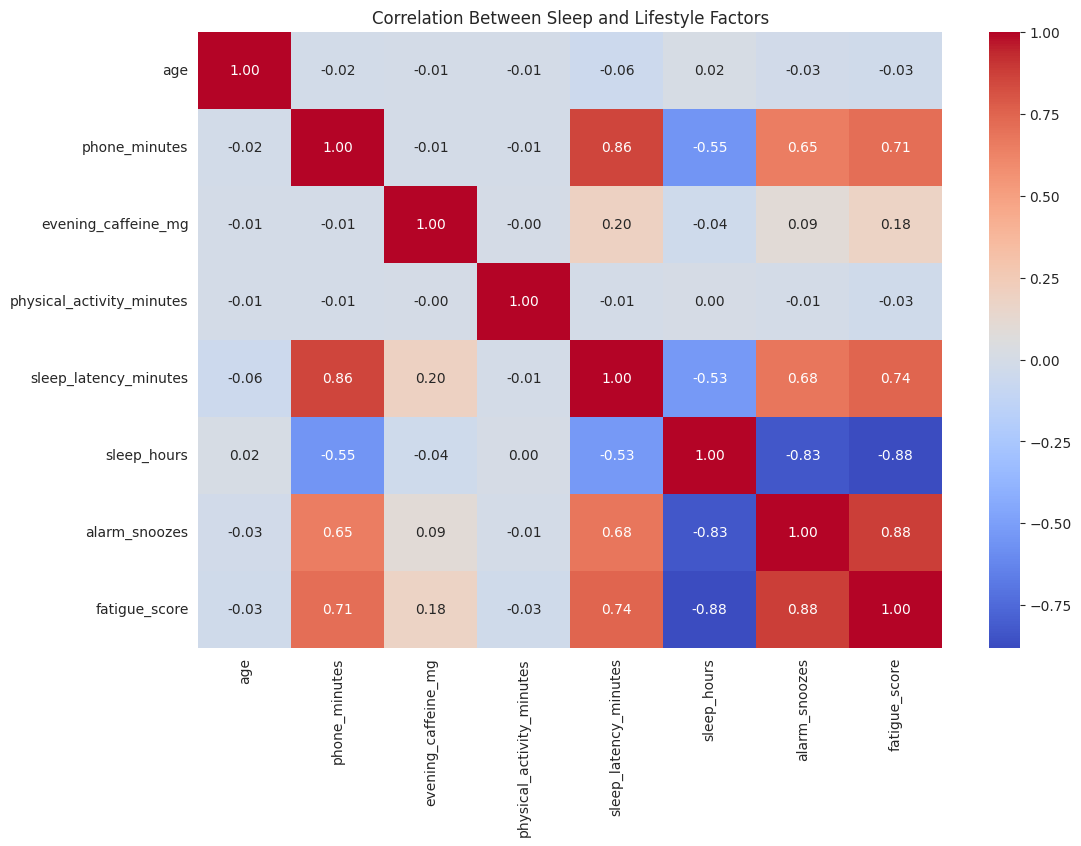

In [ ]:
numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))
plt.figure(figsize=(12,8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Sleep and Lifestyle Factors")

plt.show()

## 28. Gender-Specific Sleep Duration — FacetGrid

FacetGrid creates separate sleep-duration histograms for each recorded gender category. This allows visual comparison of distribution shapes without placing all groups on a single chart.


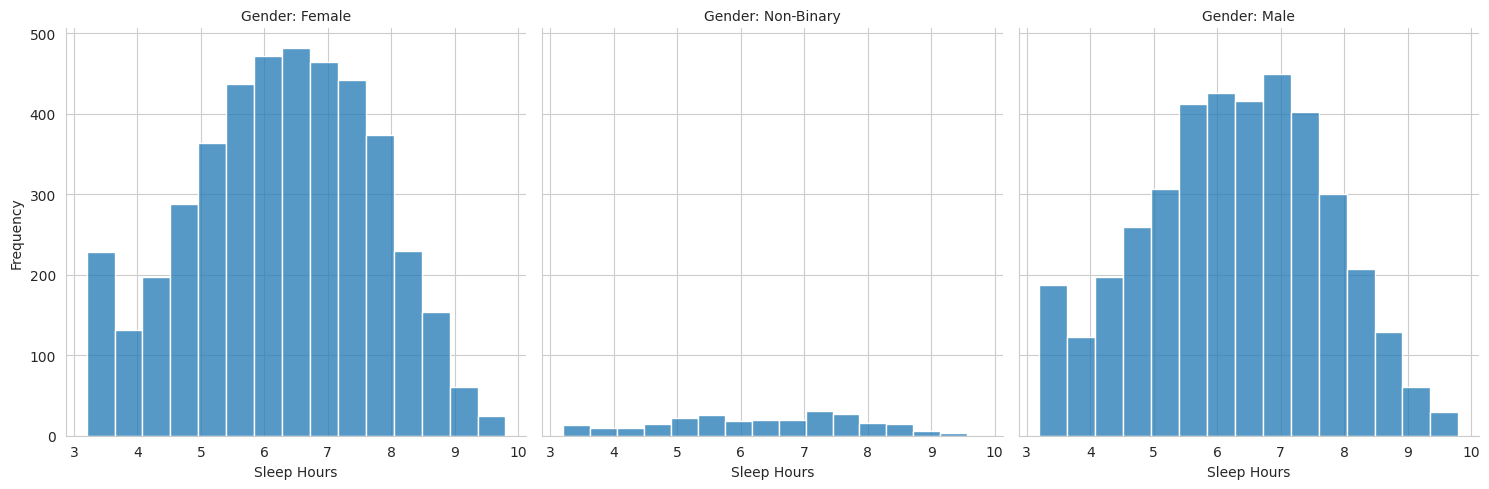

In [ ]:
g = sns.FacetGrid(
    df,
    col="gender",
    height=5
)

g.map_dataframe(
    sns.histplot,
    x="sleep_hours",
    bins=15
)

g.set_axis_labels("Sleep Hours", "Frequency")
g.set_titles("Gender: {col_name}")

plt.show()

## 29. Exporting a Publication-Quality Plot

The relationship between bedtime phone minutes and fatigue is plotted and saved as a high-resolution PNG file. Saving the image allows it to be included in a presentation or written report.


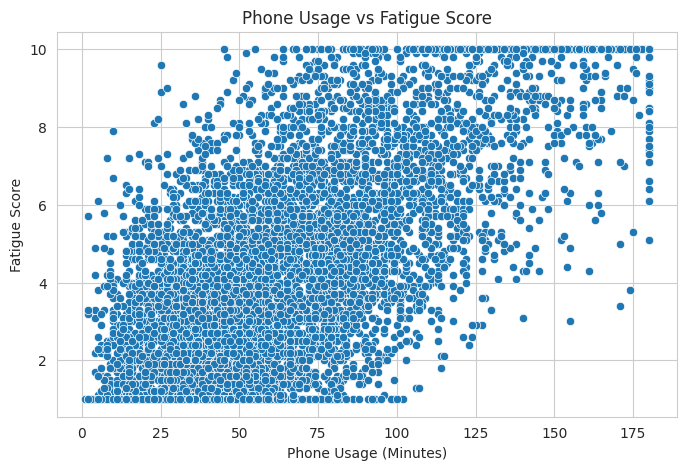

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="phone_minutes",
    y="fatigue_score"
)

plt.title("Phone Usage vs Fatigue Score")
plt.xlabel("Phone Usage (Minutes)")
plt.ylabel("Fatigue Score")

plt.savefig("phone_fatigue.png", dpi=300, bbox_inches="tight")

plt.show()

## 30. Sleep Duration Density — KDE Plot

A kernel density estimate provides a smoothed view of the sleep-duration distribution. It complements the histogram but should be interpreted cautiously near the boundaries of possible sleep hours.


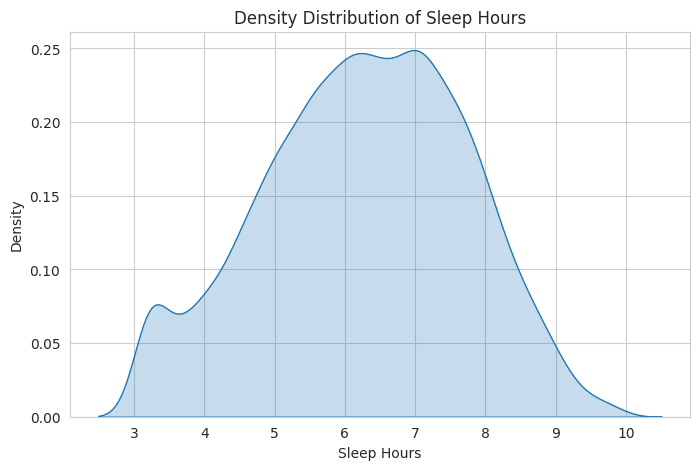

In [ ]:
plt.figure(figsize=(8,5))

sns.kdeplot(
    data=df,
    x="sleep_hours",
    fill=True
)

plt.title("Density Distribution of Sleep Hours")
plt.xlabel("Sleep Hours")
plt.ylabel("Density")

plt.show()

## Conclusion and Interpretation

This case study demonstrates a workflow for loading, cleaning, summarizing and visualizing sleep-related data. Grouped comparisons, distributions and correlations help identify associations between bedtime phone habits, sleep duration, fatigue and lifestyle factors. The direction and strength of any specific relationship should be reported only after examining the actual numerical and graphical outputs. Because the analysis is observational, it cannot establish cause and effect.

## Limitations

The dataset may contain self-reported or otherwise imperfect measurements; the notebook does not verify sample representativeness or causal mechanisms. Category boundaries are chosen for exploratory convenience. Missing-value imputation can change results. Further work could include statistical significance tests, sensitivity checks and multivariable models.

## References

- Kaggle dataset: *Sleep Debt and Screen Time: Late Night Phone Habits* (`samartalwar/sleep-debt-and-screen-time-late-night-phone-habits`).
- Pandas, NumPy, Matplotlib and Seaborn official documentation.
